# Tugas Praktikum Reinforcement Learning

* **Nama:** `Muhammad Fasya Atthaya Rosyada`
* **NRP:** `5054251006`
* **Link YT:** https://youtu.be/dctxBPLWXWE
---

| Konsep RL | Implementasi pada Proyek Gomoku $4 \times 4$ |
| :--- | :--- |
| **Environment** | Papan permainan matriks $4 \times 4$ (`GomokuEnv`) yang mengatur aturan validasi petak kosong, deteksi pola kemenangan 3-in-a-row, deteksi kondisi seri (papan penuh), serta pemberian *reward*. |
| **Agent** | Pemain AI (simbol `X` / nilai `1`) yang belajar mengambil keputusan secara mandiri tanpa dataset permainan maupun aturan strategi eksplisit. |
| **State ($s$)** | Representasi kondisi papan saat ini yang diratakan menjadi *tuple* 1D berisi 16 elemen (`0` = kosong, `1` = bidak Agent, `-1` = bidak Lawan). |
| **Action ($a$)** | Pemilihan indeks petak papan yang masih kosong ($a \in \{0, 1, \dots, 15\}$), yang dipetakan ke koordinat baris dan kolom $(r, c)$. |
| **Reward ($r$)** | Sinyal umpan balik numerik dari environment:<br>• **`+1.0`** : Agent berhasil menang (3 bidak sejajar).<br>• **`-1.0`** : Agent kalah (lawan membentuk 3 bidak sejajar).<br>• **`+0.2`** : Permainan berakhir seri (*draw* / papan penuh).<br>• **`0.0`** : Langkah normal saat permainan masih berlangsung.<br>• **`-10.0`** : Penalti jika memilih petak yang sudah terisi (dicegah dengan *action masking*). |
| **Policy ($\pi$)** | Kebijakan **$\epsilon$-greedy**: dengan probabilitas $\epsilon$ agent melakukan *exploration* (langkah acak pada petak valid), dan dengan probabilitas $1-\epsilon$ agent melakukan *exploitation* (memilih aksi dengan nilai $Q$ tertinggi). Nilai $\epsilon$ meluruh dari $1.0$ hingga $0.05$. |
| **Value ($Q(s, a)$)** | Estimasi nilai harapan imbalan jangka panjang (*expected cumulative return*) untuk setiap pasangan *state-action*, yang disimpan dalam *Q-Table* (`defaultdict`) dan diperbarui menggunakan persamaan Bellman. |

---

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt
from collections import defaultdict

class GomokuEnv:
    def __init__(self, board_size=6, win_len=4):
        self.board_size = board_size
        self.win_len = win_len
        self.reset()

    def reset(self):
        # 0: Kosong, 1: Agent (Hitam), -1: Lawan (Putih)
        self.board = np.zeros((self.board_size, self.board_size), dtype=int)
        self.done = False
        self.winner = None
        return self.get_state()

    def get_state(self):
        return tuple(self.board.flatten())

    def get_valid_actions(self):
        return [i for i, val in enumerate(self.board.flatten()) if val == 0]

    def check_winner(self, player):
        b = self.board
        n = self.board_size
        w = self.win_len

        for r in range(n):
            for c in range(n):
                if b[r, c] != player:
                    continue
                # Cek Horizontal
                if c + w <= n and all(b[r, c+i] == player for i in range(w)):
                    return True
                # Cek Vertikal
                if r + w <= n and all(b[r+i, c] == player for i in range(w)):
                    return True
                # Cek Diagonal Utama (\)
                if r + w <= n and c + w <= n and all(b[r+i, c+i] == player for i in range(w)):
                    return True
                # Cek Diagonal Sekunder (/)
                if r + w <= n and c - w + 1 >= 0 and all(b[r+i, c-i] == player for i in range(w)):
                    return True
        return False

    def step(self, action, player):
        if self.done:
            raise ValueError("Permainan sudah selesai. Panggil reset().")

        row, col = divmod(action, self.board_size)

        if self.board[row, col] != 0:
            return self.get_state(), -10.0, True

        self.board[row, col] = player

        # Cek kemenangan
        if self.check_winner(player):
            self.done = True
            self.winner = player
            reward = 1.0 if player == 1 else -1.0
            return self.get_state(), reward, True

        # Cek seri (papan penuh)
        if len(self.get_valid_actions()) == 0:
            self.done = True
            self.winner = 0
            return self.get_state(), 0.2, True

        return self.get_state(), 0.0, False

    def render(self):
        symbols = {0: '.', 1: 'X', -1: 'O'}
        print("  " + " ".join(str(i) for i in range(self.board_size)))
        for r in range(self.board_size):
            row_str = " ".join(symbols[val] for val in self.board[r])
            print(f"{r} {row_str}")
        print()

In [ ]:
class QLearningAgent:
    def __init__(self, alpha=0.1, gamma=0.95, epsilon=1.0, epsilon_decay=0.99985, epsilon_min=0.05):
        # Q-table: mapping state -> array nilai action sepanjang 36
        self.q_table = defaultdict(lambda: np.zeros(36))
        self.alpha = alpha                  # Learning rate
        self.gamma = gamma                  # Discount factor
        self.epsilon = epsilon              # Exploration rate
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

    def choose_action(self, state, valid_actions, training=True):
        if training and random.random() < self.epsilon:
            return random.choice(valid_actions)

        q_values = self.q_table[state]
        valid_q = {a: q_values[a] for a in valid_actions}
        max_q = max(valid_q.values())
        best_actions = [a for a, q in valid_q.items() if q == max_q]
        return random.choice(best_actions)

    def update(self, state, action, reward, next_state, next_valid_actions, done):
        current_q = self.q_table[state][action]
        if done or not next_valid_actions:
            target = reward
        else:
            next_max_q = max(self.q_table[next_state][a] for a in next_valid_actions)
            target = reward + self.gamma * next_max_q

        self.q_table[state][action] += self.alpha * (target - current_q)

    def decay_epsilon(self):
        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay


def opponent_policy(env, smart_prob=0.5):
    """Lawan berlatih: 50% memakai logika taktis sederhana, 50% acak."""
    valid_actions = env.get_valid_actions()
    if random.random() < smart_prob:
        for a in valid_actions:
            r, c = divmod(a, env.board_size)
            env.board[r, c] = -1
            if env.check_winner(-1):
                env.board[r, c] = 0
                return a
            env.board[r, c] = 0

        for a in valid_actions:
            r, c = divmod(a, env.board_size)
            env.board[r, c] = 1
            if env.check_winner(1):
                env.board[r, c] = 0
                return a
            env.board[r, c] = 0

    return random.choice(valid_actions)

In [ ]:
env = GomokuEnv(board_size=4, win_len=3)
agent = QLearningAgent(alpha=0.2, gamma=0.95, epsilon=1.0, epsilon_decay=0.99985, epsilon_min=0.05)
agent.q_table = defaultdict(lambda: np.zeros(env.board_size ** 2))

episodes = 30000
win_history = []
batch_size = 500
wins_in_batch = 0

print("Memulai proses pelatihan Agent Gomoku (4x4, 3-in-a-row)...")

for ep in range(1, episodes + 1):
    state = env.reset()
    done = False
    agent_turn = random.choice([True, False])
    last_agent_state = None
    last_agent_action = None

    # Curriculum Learning: 15.000 episode pertama lawan acak, sisanya lawan semi-smart
    current_smart_prob = 0.0 if ep <= 15000 else 0.5

    while not done:
        if agent_turn:
            valid_actions = env.get_valid_actions()
            action = agent.choose_action(state, valid_actions, training=True)
            next_state, reward, done = env.step(action, player=1)

            if done:
                agent.update(state, action, reward, next_state, [], True)
                if env.winner == 1:
                    wins_in_batch += 1
            else:
                last_agent_state = state
                last_agent_action = action

            state = next_state
            agent_turn = False
        else:
            opp_action = opponent_policy(env, smart_prob=current_smart_prob)
            next_state, _, done = env.step(opp_action, player=-1)

            if last_agent_state is not None:
                if done:
                    final_reward = -1.0 if env.winner == -1 else 0.2
                    agent.update(last_agent_state, last_agent_action, final_reward, next_state, [], True)
                else:
                    next_valid = env.get_valid_actions()
                    agent.update(last_agent_state, last_agent_action, 0.0, next_state, next_valid, False)

            state = next_state
            agent_turn = True

    agent.decay_epsilon()

    if ep % batch_size == 0:
        win_rate = (wins_in_batch / batch_size) * 100
        win_history.append(win_rate)
        wins_in_batch = 0
        if ep % 5000 == 0:
            print(f"Episode {ep}/{episodes} | Win Rate: {win_rate:.1f}% | Epsilon: {agent.epsilon:.3f} | States Dipelajari: {len(agent.q_table)}")

print("Pelatihan selesai!")

Memulai proses pelatihan Agent Gomoku (4x4, 3-in-a-row)...
Episode 5000/30000 | Win Rate: 53.0% | Epsilon: 0.472 | States Dipelajari: 15464
Episode 10000/30000 | Win Rate: 57.8% | Epsilon: 0.223 | States Dipelajari: 27202
Episode 15000/30000 | Win Rate: 67.0% | Epsilon: 0.105 | States Dipelajari: 36151
Episode 20000/30000 | Win Rate: 50.0% | Epsilon: 0.050 | States Dipelajari: 40101
Episode 25000/30000 | Win Rate: 52.6% | Epsilon: 0.050 | States Dipelajari: 43517
Episode 30000/30000 | Win Rate: 55.8% | Epsilon: 0.050 | States Dipelajari: 46885
Pelatihan selesai!


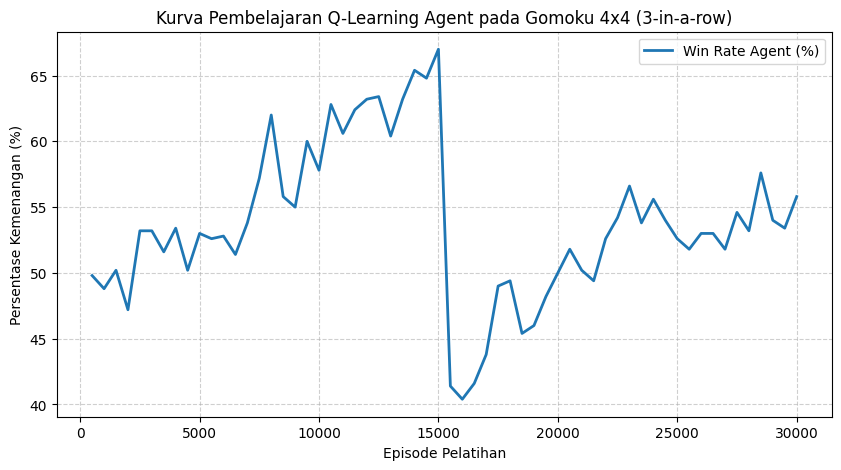

=== HASIL EVALUASI 1.000 PERTANDINGAN ===
Melawan Random Policy     -> Menang: 73.6% | Kalah: 26.4% | Seri: 0.0%
Melawan Semi-Smart Policy -> Menang: 60.6% | Kalah: 39.4% | Seri: 0.0%

=== SIMULASI LANGKAH TERAKHIR PERTANDINGAN ===
  0 1 2 3
0 O . . .
1 . X . .
2 O . X .
3 . . . X

Pemenang: Agent (X)


In [ ]:
plt.figure(figsize=(10, 5))
x_axis = np.arange(batch_size, episodes + 1, batch_size)
plt.plot(x_axis, win_history, label='Win Rate Agent (%)', color='#1f77b4', linewidth=2)
plt.title('Kurva Pembelajaran Q-Learning Agent pada Gomoku 4x4 (3-in-a-row)')
plt.xlabel('Episode Pelatihan')
plt.ylabel('Persentase Kemenangan (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

def evaluate_agent(env, agent, num_games=1000, smart_prob=0.5):
    wins, losses, draws = 0, 0, 0
    for _ in range(num_games):
        state = env.reset()
        done = False
        agent_turn = random.choice([True, False])
        while not done:
            if agent_turn:
                valid = env.get_valid_actions()
                action = agent.choose_action(state, valid, training=False)
                state, _, done = env.step(action, player=1)
                agent_turn = False
            else:
                opp_action = opponent_policy(env, smart_prob=smart_prob)
                state, _, done = env.step(opp_action, player=-1)
                agent_turn = True
        if env.winner == 1:
            wins += 1
        elif env.winner == -1:
            losses += 1
        else:
            draws += 1
    return wins, losses, draws

w_rand, l_rand, d_rand = evaluate_agent(env, agent, num_games=1000, smart_prob=0.0)
w_smart, l_smart, d_smart = evaluate_agent(env, agent, num_games=1000, smart_prob=0.5)

print("=== HASIL EVALUASI 1.000 PERTANDINGAN ===")
print(f"Melawan Random Policy     -> Menang: {w_rand/10:.1f}% | Kalah: {l_rand/10:.1f}% | Seri: {d_rand/10:.1f}%")
print(f"Melawan Semi-Smart Policy -> Menang: {w_smart/10:.1f}% | Kalah: {l_smart/10:.1f}% | Seri: {d_smart/10:.1f}%")

print("\n=== SIMULASI LANGKAH TERAKHIR PERTANDINGAN ===")
state = env.reset()
done = False
agent_turn = True
while not done:
    if agent_turn:
        action = agent.choose_action(state, env.get_valid_actions(), training=False)
        state, _, done = env.step(action, player=1)
        agent_turn = False
    else:
        action = opponent_policy(env, smart_prob=0.5)
        state, _, done = env.step(action, player=-1)
        agent_turn = True

env.render()
print("Pemenang:", "Agent (X)" if env.winner == 1 else ("Lawan (O)" if env.winner == -1 else "Seri"))

## Analisis Hasil Eksperimen

Berdasarkan eksperimen pelatihan selama $30.000$ episode pada papan Gomoku berukuran $4 \times 4$ (3-in-a-row) serta pengujian evaluasi sebanyak $1.000$ pertandingan (dengan $\epsilon = 0$ / *pure exploitation*), diperoleh beberapa temuan utama:

### A. Dinamika Kurva Pembelajaran & Efek *Curriculum Learning*
Grafik perkembangan *win rate* selama $30.000$ episode terbagi ke dalam dua fase yang jelas seiring penerapan strategi *Curriculum Learning*:

1. **Fase 1 — Eksplorasi & Pembelajaran Pola Dasar (Episode $1 - 15.000$, *Random Opponent*):**
   * Pada episode $5.000$ ($\epsilon = 0,472$), *win rate* agent berada di angka **53,0%** karena kebijakan ($\pi$) masih didominasi oleh langkah acak (*exploration*).
   * Seiring meluruhnya tingkat eksplorasi ($\epsilon \rightarrow 0,105$), agent mulai mengandalkan nilai $Q(s,a)$ terbaik yang telah dipelajari (*exploitation*), sehingga *win rate* meningkat menjadi **57,8%** (episode $10.000$) dan mencapai puncaknya di **67,0%** pada episode $15.000$.

2. **Fase 2 — Adaptasi Strategi Bertahan (Episode $15.001 - 30.000$, *Semi-Smart Opponent*):**
   * Tepat setelah episode $15.000$, tingkat kecerdasan lawan ditingkatkan menjadi *Semi-Smart Policy* (`smart_prob = 0.5`). Hal ini menyebabkan *win rate* sempat turun dari **67,0%** menjadi **50,0%** pada episode $20.000$, karena pola serangan langsung yang efektif melawan pemain acak kini mulai diblokir oleh lawan.
   * Meskipun nilai $\epsilon$ sudah minimal ($0,050$), agent tetap mampu menyesuaikan bobot *Q-Table*-nya untuk menutup celah pertahanan dan membangun variasi ancaman baru, sehingga *win rate* kembali naik secara bertahap menjadi **52,6%** (episode $25.000$) dan ditutup di **55,8%** pada episode $30.000$.

---

### B. Pertumbuhan Ruang Keadaan (*State Space Exploration*)
Hingga akhir episode ke-$30.000$, *Q-Table* mencatat sebanyak **46.885 *state* unik** yang dikunjungi oleh agent:
* Pada $15.000$ episode pertama, jumlah *state* bertambah cukup cepat (mencapai $36.151$ *state*) karena nilai $\epsilon$ yang tinggi mendorong agent mencoba berbagai variasi konfigurasi papan.
* Pada $15.000$ episode terakhir, laju penambahan *state* baru melambat drastis (hanya bertambah $10.734$ *state*), menandakan bahwa agent mulai sering mengunjungi ulang konfigurasi papan yang sudah dikenal dan memperdalam akurasi estimasi nilai $Q(s,a)$ pada *state-state* krusial.

---

### C. Hasil Evaluasi Akhir ($1.000$ Pertandingan Tanpa Eksplorasi)
Setelah pelatihan selesai, kebijakan optimal agent ($\pi^*(s) = \arg\max_a Q(s,a)$) diuji dalam $1.000$ pertandingan tanpa langkah acak ($\epsilon = 0$) dan giliran pertama yang diacak:

| Jenis Lawan Uji (*Sparring Policy*) | Menang (*Win*) | Kalah (*Loss*) | Seri (*Draw*) |
| :--- | :---: | :---: | :---: |
| **Random Policy** (`smart_prob = 0.0`) | **73,6%** | 26,4% | 0,0% |
| **Semi-Smart Policy** (`smart_prob = 0.5`) | **60,6%** | 39,4% | 0,0% |

**Analisis Hasil Evaluasi:**
* **Peningkatan Performa saat Evaluasi ($\epsilon = 0$):** Saat faktor eksplorasi dimatikan sepenuhnya, *win rate* agent melawan *Semi-Smart Policy* melonjak dari **55,8%** (di akhir pelatihan) menjadi **60,6%**. Hal ini membuktikan bahwa kebijakan optimal di dalam *Q-Table* sudah terbentuk dengan baik dan penurunan skor selama pelatihan sebagian disebabkan oleh sisa langkah acak ($\epsilon = 0,05$).
* **Dominasi atas *Random Policy*:** Melawan pemain acak, agent mencapai tingkat kemenangan **73,6%**. Kekalahan sebesar 26,4% umumnya terjadi ketika lawan mendapat giliran pertama (*first-move advantage*) dan secara kebetulan menyusun 3 bidak pada konfigurasi papan yang jarang ditemui saat pelatihan.
* **Nol Hasil Seri (0,0% Draw):** Pada papan berukuran kecil ($4 \times 4$) dengan syarat menang yang pendek (3-in-a-row), permainan selalu berakhir menentukan pemenang sebelum seluruh 16 petak terisi penuh.
* **Bukti Visual Simulasi Akhir:** Pada papan simulasi akhir, terlihat bahwa ketika lawan (`O`) berupaya membangun serangan vertikal pada kolom `0` (baris `0` dan `2`), agent (`X`) berhasil membentuk garis kemenangan diagonal utama secara bersih pada koordinat `(1,1) -> (2,2) -> (3,3)`.